In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import yaml
import seaborn as sns
from utils.plots import *

from numpyro import distributions as dist
from utils.relaxations import relax_factors
from utils.relaxations import time_ablate_val
from utils.relaxations import shape_ablate_val
from matplotlib.patches import Ellipse
from scipy.stats import chi2

from utils.figures import plot_metrics
from matplotlib.gridspec import GridSpec


FIG = 'fig_relaxations'

config_fpath = Path(f'{FIG}.yml')
data_fpath = Path(f'{FIG}_df.csv')
param_dir = Path('../../prior_params')

with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
df = pd.read_csv(data_fpath)


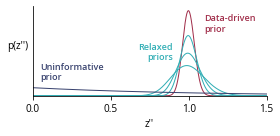

In [3]:
alpha_zpp = np.load(param_dir / 'alpha_zpp.npy')

def subfigure_time_demo():

    x = np.linspace(0, 1.5, 1000)
    y = np.exp(dist.Gamma(alpha_zpp, alpha_zpp).log_prob(x))

    plt.plot(x, y, label='original', c=cp[1])

    for k, factor in relax_factors.items():
        alpha_zpp_relax = alpha_zpp / factor
        y = np.exp(dist.Gamma(alpha_zpp_relax, alpha_zpp_relax).log_prob(x))
        label = 'relaxed' if k=='A' else None
        plt.plot(x, y, label=label, c=cp[3])

    y = np.exp(dist.Gamma(time_ablate_val, time_ablate_val).log_prob(x))
    plt.plot(x, y, label='uninformative', c=cp[0])

    plt.xticks([0, 0.5, 1, 1.5])
    # plt.legend(loc='upper left', frameon=False, borderpad=0)
    plt.xlabel("z''")
    plt.ylabel("p(z'')", rotation=0, labelpad=15)
    plt.yticks([])
    plt.ylim(0, None)

    plt.text(1.1, 8, 'Data-driven\nprior', color=cp[1], size=9, fontdict={'weight':'semibold'})
    plt.text(0.9, 4.5, 'Relaxed\npriors', color=cp[3], size=9, fontdict={'weight':'semibold'}, ha='right')
    plt.text(0.05, 2, 'Uninformative\nprior', color=cp[0], size=9, fontdict={'weight':'semibold'})


plt.figure(figsize=(4,2))
subfigure_time_demo()
plt.show()


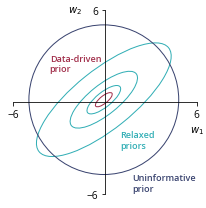

In [4]:
mu_w = np.load(param_dir / 'mu_w.npy')
L_w = np.load(param_dir / 'L_w.npy')
Sigma_w = L_w @ L_w.T

mu = mu_w[:2]
Sigma = Sigma_w[:2,:2]


def confidence_ellipse(mu, Sigma, C=0.95, ax=None, c=cp[0], **kwargs):
    if ax is None:
        ax = plt.gca()
    
    eigvals, eigvecs = np.linalg.eigh(Sigma)
    order = eigvals.argsort()[::-1]
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    
    s = chi2.ppf(C, df=2)
    width, height = 2 * np.sqrt(eigvals * s)
    angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))
    ell = Ellipse(xy=mu, width=width, height=height, angle=angle, facecolor='none', ec=c, **kwargs)
    ax.add_patch(ell)
    return ell

def subfigure_shape_demo():

    xyminmax = 6
    xmin, xmax = -xyminmax, xyminmax
    ymin, ymax = -xyminmax, xyminmax
    plt.gca().spines['left'].set_position('zero')
    plt.gca().spines['bottom'].set_position('zero')
    plt.xlim(xmin, xmax)
    plt.ylim(ymin, ymax)
    plt.xticks([xmin, xmax])
    plt.yticks([ymin, ymax])

    confidence_ellipse(mu, Sigma, C=0.95, ax=plt.gca(), c=cp[1])

    for k, factor in relax_factors.items():
        Sigma_relax = Sigma * factor**2
        label = 'relaxed' if k=='A' else None
        confidence_ellipse(mu, Sigma_relax, C=0.95, ax=plt.gca(), c=cp[3])

    Sigma_ablate = np.eye(2) * shape_ablate_val**2
    confidence_ellipse(mu, Sigma_ablate, C=0.95, ax=plt.gca(), c=cp[0])

    plt.gca().set_xlabel(r'$w_1$', x=1, y=1, ha='center', va='top')
    plt.gca().set_ylabel(r'$w_2$', x=1, y=1, ha='right', va='center', rotation=0)

    plt.text(-3.6,2, 'Data-driven\nprior', color=cp[1], size=9, fontdict={'weight':'semibold'})
    plt.text(1, -3, 'Relaxed\npriors', color=cp[3], size=9, fontdict={'weight':'semibold'})
    plt.text(1.8, -5.8, 'Uninformative\nprior', color=cp[0], size=9, fontdict={'weight':'semibold'}, )


plt.figure(figsize=(3,3))
subfigure_shape_demo()
plt.show()


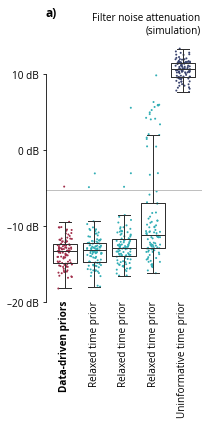

In [5]:
def subfigure_x(y,  sub='x)', ylim=None, yticks=None, yticklabels=None, debug=False,
                hidexticks=False):
    title = y['name']
    metric = y['metric']
    methods = [x['method'] for x in y['x']]
    names = [x['name'] for x in y['x']]
    log = y.get('log', False)

    df_exp = df[df['exp']==y['experiment']]
    # df_temp = plot_metrics(df_exp, metric, methods, names, log=log)
    df_baseline = df.iloc[~df['method'].str.contains('bpd')]
    df_bpd = df_exp.iloc[df['method'].str.contains('bpd')]
    df_temp = plot_metrics(df_bpd, metric, methods, names, log=log)

    plt.gca().set_xmargin(0.05)

    plt.gca().tick_params(axis="x", direction="in", pad=-66)

    if not debug:
        plt.minorticks_off()
    plt.ylim(ylim)
    plt.yticks(yticks, yticklabels)
    
    plt.plot([np.nan], [np.nan], lw=0, label=title)
    lgnd = plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
                      ncol=3, columnspacing=1.5,
                      frameon=False, borderpad=0.0, borderaxespad=0.1,
                      handlelength=1.5, handletextpad=0.5)
    for t in lgnd.get_texts():
        t.set_ha('right')

    sns.despine(ax=plt.gca(), bottom=(not debug), left=(len(yticks)==0), trim=True)
    labels = plt.gca().get_xticklabels()
    labels[0].set_weight('bold')

    plt.axhline(df_baseline[metric].median(), zorder=-1, c=cp[-1])

    if hidexticks:
        plt.xticks([], [])

    plt.title(sub, loc='left', pad=20, fontdict={'fontweight': 'bold'})

    return df_temp


plt.figure(figsize=(3,6))
ylim = (-28.5, 15)
yticks = [-20, -10, 0, 10]
yticklabels = ['–20 dB', '–10 dB', '0 dB', '10 dB']
subfigure_x(config['y'][0], 'a)', ylim, yticks, yticklabels)
plt.show()

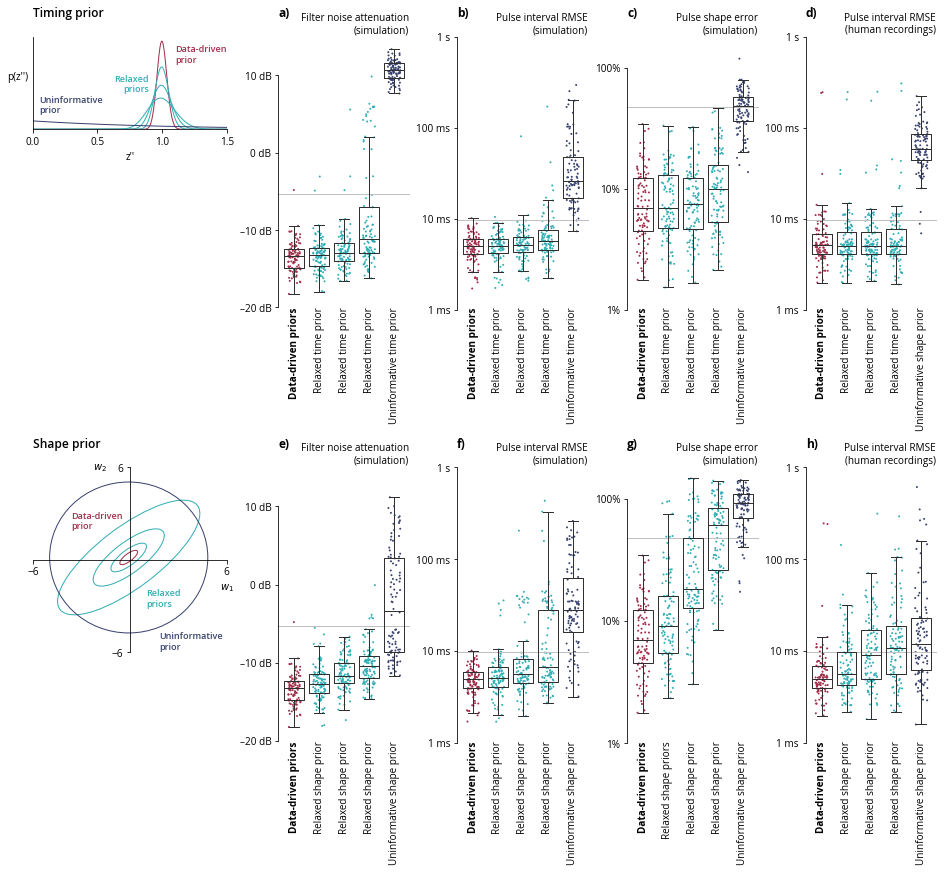

In [6]:
fig = plt.figure(figsize=(13,12), layout="constrained")
gs = GridSpec(4,5, figure=fig,
              height_ratios=np.array([2,4,4,2]),
              width_ratios=[3.5,2.375,2.375,2.375,2.375],
              hspace=0.03, wspace=0.03)

fig.add_subplot(gs[0, 0])
subfigure_time_demo()
plt.title('Timing prior', loc='left', fontdict={'weight':'semibold'}, pad=20)

fig.add_subplot(gs[2, 0])
subfigure_shape_demo()
plt.title('Shape prior', loc='left', fontdict={'weight':'semibold'}, pad=20)

ylim = (-28.5, 15)
yticks = [-20, -10, 0, 10]
yticklabels = ['–20 dB', '–10 dB', '0 dB', '10 dB']

fig.add_subplot(gs[:2, 1])
subfigure_x(config['y'][0], 'a)', ylim, yticks, yticklabels)
fig.add_subplot(gs[2:, 1])
subfigure_x(config['y'][4], 'e)', ylim, yticks, yticklabels)

ylim = (0.0002, None)
yticks = [0.001, 0.01, 0.1, 1]
yticklabels = ['1 ms', '10 ms', '100 ms', '1 s']

fig.add_subplot(gs[:2, 2])
subfigure_x(config['y'][1], 'b)', ylim, yticks, yticklabels)
fig.add_subplot(gs[:2, 4])
subfigure_x(config['y'][3], 'd)', ylim, yticks, yticklabels)
fig.add_subplot(gs[2:, 2])
subfigure_x(config['y'][5], 'f)', ylim, yticks, yticklabels)
fig.add_subplot(gs[2:, 4])
subfigure_x(config['y'][7], 'h)', ylim, yticks, yticklabels)

ylim = (0.003, 1.8)
yticks = [0.01, 0.1, 1]
yticklabels = ['1%', '10%', '100%']

fig.add_subplot(gs[:2, 3])
subfigure_x(config['y'][2], 'c)', ylim, yticks, yticklabels)
fig.add_subplot(gs[2:, 3])
subfigure_x(config['y'][6], 'g)', ylim, yticks, yticklabels)

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()
